In [2]:
import numpy as np
import pandas as pd
import cv2
from matplotlib import pyplot as plt
from numpy.linalg import inv
import os

from colormath.color_conversions import convert_color
from colormath.color_objects import LabColor, XYZColor
from colormath.color_diff import delta_e_cie2000

import skimage
from skimage.color import rgb2lab, lab2rgb

from scipy.interpolate import BSpline, make_interp_spline

from scipy.optimize import minimize
from scipy.optimize import dual_annealing
from scipy.optimize import least_squares
from scipy.optimize import basinhopping

from numpy.random import random
from numpy.random import rand

# Spectrum Transfer Model

In [3]:
st_extend_20 = 0
st_extend_21 = 1
st_extend_30 = 2

class SpectrumTransfer:
    
    def __init__(self):
        self.extend_mode = 0
        self.pca_eigenvectors = None
        self.pca_mean = None
        self.M = None
        self.TransM = None
        self.TransMin = 0.0
        self.TransMax = 1.0
        
    def get_extend_color(self, src_rgb):
        
        extend = None

        if self.extend_mode == 0:
            extend = np.array([src_rgb[:,0], src_rgb[:,1], src_rgb[:,2], np.power(src_rgb[:,0],2), np.power(src_rgb[:,1],2), np.power(src_rgb[:,2],2)])
        elif self.extend_mode == 1:
            extend = np.array([src_rgb[:,0], src_rgb[:,1], src_rgb[:,2], np.power(src_rgb[:,0],2), np.power(src_rgb[:,1],2), np.power(src_rgb[:,2],2),src_rgb[:,0]* src_rgb[:,1],src_rgb[:,0]* src_rgb[:,2],src_rgb[:,1]* src_rgb[:,2]])
        elif self.extend_mode == 2:
            extend = np.array([src_rgb[:,0], src_rgb[:,1], src_rgb[:,2], np.power(src_rgb[:,0],2), np.power(src_rgb[:,1],2), np.power(src_rgb[:,2],2),src_rgb[:,0]* src_rgb[:,1],src_rgb[:,0]* src_rgb[:,2],src_rgb[:,1]* src_rgb[:,2], np.power(src_rgb[:,0],3), np.power(src_rgb[:,1],3), np.power(src_rgb[:,2],3)])

        return extend
    
    def prepare(self):
        self.TransM = np.dot(self.M.T, self.pca_eigenvectors)
        return
     
    def train(self, extend_mode, train_spec, train_color, pca_comps=6):
        self.extend_mode = extend_mode
        
        pca = PCA(n_components=pca_comps, whiten=False)
        pca.fit(train_spec)
        
        self.pca_eigenvectors = pca.components_
        self.pca_mean = pca.mean_

        trans_pca_a = pca.transform(train_spec)
        trans_extend_c = self.get_extend_color(train_color)

        self.M = np.dot(trans_pca_a.T, pinv(trans_extend_c))

        self.prepare()
        
        c = np.arange(256)
        all_color = np.array(np.meshgrid(c, c, c)).T.reshape(-1,3)

        self.TransMin = 0.0
        self.TransMax = 1.0
        
#         min_v = 100.0
#         max_v = -100.0

#         split_num = 64
#         batch_size = int(all_color.shape[0] / split_num)

#         for n in range(64):
#             test_c = all_color[n * batch_size: (n+1) *batch_size, :]
#             test_s = self.transfer(test_c)
#             batch_min = np.min(test_s)
#             batch_max = np.max(test_s)

#             min_v = min(min_v, batch_min)
#             max_v = max(max_v, batch_max)

#         self.TransMin = min_v
#         self.TransMax = max_v
        
        return
    
    def save(self, setup_file):
        np.savez(setup_file, a=self.M, b=self.pca_eigenvectors, c=self.pca_mean, d=np.array([self.TransMin,self.TransMax]), e=np.array([self.extend_mode]))

        
    def save_files(self, setup_path):
        np.save(os.path.join(setup_path, "spec_a.npy"), self.M)
        np.save(os.path.join(setup_path, "spec_b.npy"), self.pca_eigenvectors)
        np.save(os.path.join(setup_path, "spec_c.npy"), self.pca_mean)
        np.save(os.path.join(setup_path, "spec_d.npy"), np.array([self.TransMin,self.TransMax]))
        np.save(os.path.join(setup_path, "spec_e.npy"), np.array([self.extend_mode]))
        
    def load(self, setup_file):
        weight = np.load(setup_file)
        
        self.M = weight["a"]
        self.pca_eigenvectors = weight["b"]
        self.pca_mean = weight["c"]
        
#         self.TransMin = weight['d'][0]
#         self.TransMax = weight['d'][1]
        
        self.extend_mode = weight['e'][0]
        
        self.prepare()
        
        return
 
    def transfer1D(self, src_data):
        
        src_data = src_data.astype(np.float32)

        tar_sepc = np.dot(self.get_extend_color(src_data).T, self.TransM) + self.pca_mean
        
        tar_sepc = (tar_sepc - self.TransMin) / (self.TransMax - self.TransMin)

        return tar_sepc
    
    def transfer(self, src_data):
        
        src_data = src_data.astype(np.float32)
        
        src_shape = src_data.shape

        if len(src_shape) >= 3:
            src_data = src_data.reshape(-1, src_shape[-1])

        tar_sepc = np.dot(self.get_extend_color(src_data).T, self.TransM) + self.pca_mean

        if len(src_shape) >= 3:
            tar_sepc = tar_sepc.reshape(src_shape[0:-1] + tuple([self.pca_mean.shape[0]]))
        
        tar_sepc = (tar_sepc - self.TransMin) / (self.TransMax - self.TransMin)
        
        return tar_sepc

# Color Reproduce Model

In [4]:
class ColorReproducer:
    
    def __init__(self): 
        self.light_spec = None
        self.cmf = None
        self.ma = None
        self.d65 = np.array([0.95047, 1.00000000, 1.08883])
        self.is_ignore_ca = False
        
        self.light_spec_x3 = None
        self.cal_fact = None
        self.k = None
        self.white_light_k = None
        
    def prepare(self):
        self.light_spec_x3 = np.array([self.light_spec,self.light_spec,self.light_spec]).T 
        self.cal_fact = self.cmf * self.light_spec_x3
        self.k = 100.0 / sum(self.cal_fact[:,1])
        self.white_light_k = np.dot(self.cmf.T, self.light_spec) * (self.k / 100.0)
        self.cal_fact = self.cal_fact * self.k
 
        return

    def load(self, setup_path):
        self.light_spec = np.loadtxt(os.path.join(setup_path, 'CR_light.txt'))
        self.cmf = np.loadtxt(os.path.join(setup_path, 'CR_cmf.txt'))
        self.ma = np.loadtxt(os.path.join(setup_path, 'CR_ma.txt'))
        
        self.prepare()
        return
        
    def reproduce(self, img_spec, gain = 1.0, is_normalize = False, filter_band = None):
        
        dims = len(img_spec.shape)
        
        if dims == 2:
            hw,c = img_spec.shape
        elif dims == 3:
            h,w,c = img_spec.shape
        
        img_spec = img_spec.reshape((-1,c));
        
        fact = None
        
        if self.is_ignore_ca:
            fact = self.cal_fact
        else:
            fact = inv(self.ma).dot(np.diag(self.ma.dot(self.d65) / self.ma.dot(self.white_light_k))).dot(self.ma)
            fact = fact.dot(self.cal_fact.T).T 
            
        op_ref_spec = None
        
        if filter_band is not None:

            filter_band_set = filter_band - 380

            mask = np.zeros((w*h, 401))
            
            mask[:,filter_band_set] = 1

            op_ref_spec = img_spec * mask * gain

        else:

            op_ref_spec = img_spec * gain
        
        
        if is_normalize: 
            
            img_rep_xyz = op_ref_spec.dot(fact)

            min_v = img_rep_xyz.min()
            max_v = img_rep_xyz.max()

            img_rep_xyz = (img_rep_xyz - min_v) / (max_v - min_v) * 255.0
            
        else:
            
            img_rep_xyz = op_ref_spec.dot(fact) / 100.0 * 255.0
        
#         print('min', np.min(img_rep_xyz))
#         print('max', np.max(img_rep_xyz))
        
        img_rep_xyz.reshape(-1, 3)
        m = np.array([[3.2404542, -1.5371385, -0.4985314], [-0.9692660,  1.8760108,  0.0415560], [ 0.0556434, -0.2040259,  1.0572252]])
#         m = np.array([[0.4124564,0.3575761,  0.1804375], [0.2126729,  0.7151522,  0.0721750], [0.0193339,  0.1191920,  0.9503041]])
        m = m.T

        img_rep_rgb = np.dot(img_rep_xyz, m)
        
        img_rep_rgb[img_rep_rgb<0] = 0
        img_rep_rgb[img_rep_rgb>255] = 255
        img_rep_rgb = img_rep_rgb.astype('uint8')
        
        if dims == 2:
            img_rep_rgb = img_rep_rgb.reshape(hw, 3)
        elif dims == 3:
            img_rep_rgb = img_rep_rgb.reshape(h, w, 3)

#         if dims == 2:
#             img_rep_xyz = img_rep_xyz.reshape(hw, 1, 3).astype('uint8')
#         elif dims == 3:
#             img_rep_xyz = img_rep_xyz.reshape(h, w, 3).astype('uint8')
            
#         img_rep_rgb = cv2.cvtColor(img_rep_xyz, cv2.COLOR_XYZ2RGB)
        
#         if dims == 2:
#             img_rep_rgb = img_rep_rgb.reshape(hw, 3)
            
        return img_rep_rgb

# Functions

In [5]:
def srgb_to_linsrgb(srgb):
    """Convert sRGB values to physically linear ones. The transformation is
    uniform in RGB, so *srgb* can be of any shape.
    *srgb* values should range between 0 and 1, inclusively.
    """
    gamma = ((srgb + 0.055) / 1.055)**2.4
    scale = srgb / 12.92
    return np.where(srgb > 0.04045, gamma, scale)


def linsrgb_to_srgb(linsrgb):
    """Convert physically linear RGB values into sRGB ones. The transform is
    uniform in the components, so *linsrgb* can be of any shape.
    *linsrgb* values should range between 0 and 1, inclusively.
    """
    # From Wikipedia, but easy analogue to the above.
    gamma = 1.055 * linsrgb**(1./2.4) - 0.055
    scale = linsrgb * 12.92
    return np.where(linsrgb > 0.0031308, gamma, scale)

In [6]:
skimage.color.rgb2lab(np.array([1.0,0.0,0.0]))

array([53.24058794, 80.09230823, 67.20275104])

In [7]:
def cal_delta_e_cie2000_lab(lab_src, lab_test):
    
    errs = np.zeros(lab_src.shape[0])
    
    for i in range(lab_src.shape[0]):
        
        color0 = LabColor(lab_l=lab_src[i,0], lab_a=lab_src[i,1], lab_b=lab_src[i,2])
        color1 = LabColor(lab_l=lab_test[i,0], lab_a=lab_test[i,1], lab_b=lab_test[i,2])

        errs[i] = delta_e_cie2000(color0, color1)
        
    return errs

def cal_delta_e_cie2000_rgb(rgb_src, rgb_test):
    
    lab_src = rgb2lab(rgb_src / 255.0)
    lab_test = rgb2lab(rgb_test / 255.0)
    
    errs = np.zeros(lab_src.shape[0])
    
    for i in range(lab_src.shape[0]):
        
        color0 = LabColor(lab_l=lab_src[i,0], lab_a=lab_src[i,1], lab_b=lab_src[i,2])
        color1 = LabColor(lab_l=lab_test[i,0], lab_a=lab_test[i,1], lab_b=lab_test[i,2])

        errs[i] = delta_e_cie2000(color0, color1)
    
    # ignore gray
#     return errs[:-6]

    return errs

def rmse(errs):
    return np.sqrt(((errs) ** 2).mean())

In [8]:
def plot_diff(rgb1, rgb2):
    
    errs = cal_delta_e_cie2000_rgb(rgb1, rgb2)
    
    plt.figure(figsize=(4, 14))
    plt.axis('off')
    plt.xlim(0, 30)
    plt.ylim(-2, 26)

    plt.annotate('c1.', (8, 25), fontsize = 20)
    plt.annotate('c2.', (16, 25), fontsize = 20)
    plt.annotate('CIEDE2000', (24, 25), fontsize = 20)

    plt.annotate('mean', (16, -1), fontsize = 20)
    plt.annotate('%.2f' %(np.mean(errs)), (26, -1), fontsize = 20)

    plt.annotate('rmse', (16, -2), fontsize = 20)
    plt.annotate('%.2f' %(rmse(errs)), (26, -2), fontsize = 20)
    
    for i in range(24):

        now_c1 = rgb1[i,:]
        now_c2 = rgb2[i,:]

        plt.scatter([10], [24 - i], marker='s', s = 500, color = (now_c1[0]/255, now_c1[1]/255, now_c1[2]/255))
        plt.scatter([18], [24 - i], marker='s', s = 500, color = (now_c2[0]/255, now_c2[1]/255, now_c2[2]/255))

        plt.annotate('%.2f' %(errs[i]), (26, 24 - i - 0.2), fontsize = 20)

    plt.show()

# Initial data

In [9]:
# standard data
# 24 std, wli, nbi color

std24 = np.load('data_std.npy')
wlis = np.load('data_wli.npy')
nbis = np.load('data_nbi_sim1.npy')
caps = np.load('data_cap1.npy')

In [10]:
# initial SpectrumTransfer and ColorReproducer

transfer = SpectrumTransfer()
transfer.load("weight.npz")

reproducer = ColorReproducer()
reproducer.load('cr_weights')

In [11]:
# system lighting
light_d65 = np.loadtxt(r'lights\D65.txt').T

# olympus lighting
light_wli = np.loadtxt('Light_WLI.txt').T
light_nbi = np.loadtxt('Light_NBI.txt').T

In [12]:
# transfer wli to spectrum
wli_specs = transfer.transfer1D(wlis)

# Optimize - Color transfer matrix, Cap to WLI (without spectrum)

In [14]:
def color_transfer(src_data, m):
    
    data_shape = src_data.shape
    
    tar_data = src_data.reshape(-1, data_shape[-1])
    
    tar_data = srgb_to_linsrgb(tar_data / 255.0)
    tar_data = np.dot(tar_data, m)
    tar_data = linsrgb_to_srgb(tar_data) * 255
    
    tar_data[tar_data<0] = 0
    tar_data[tar_data>255] = 255
    tar_data = tar_data.astype('uint8')
    tar_data = tar_data.reshape(data_shape)
    
    return tar_data
    
def objective(m):
    
    sim_wlis = color_transfer(caps, m.reshape(3,3))
     
    errs = cal_delta_e_cie2000_rgb(wlis[:], sim_wlis[:])

    return rmse(errs)

# define range for input
r_min, r_max = -1.0, 1.0

v0 = rand(9)
bounds = [[r_min, r_max]] * 9
result = dual_annealing(objective, bounds, x0=v0)

# v0 = rand((int(400 / cmf_gap + 1)) * 3) * 2
# result = basinhopping(objective, v0)

# summarize the result
print('Status : %s' % result['message'])
print('Total Evaluations: %d' % result['nfev'])

# evaluate solution
solution = result['x']
evaluation = objective(solution)

print('rmse', evaluation)

C:\Users\Tony\AppData\Local\Temp\ipykernel_18888\505996063.py:17: RuntimeWarning: invalid value encountered in power
  gamma = 1.055 * linsrgb**(1./2.4) - 0.055


Status : ['Maximum number of iteration reached']
Total Evaluations: 19141
rmse 9.881129871511682


In [15]:
# update
wli_m = solution.reshape(3,3)

# wli_m = wli_m * 1.2

wli_m

array([[ 0.40682918, -0.41299621, -0.30044331],
       [-0.15124288,  0.80917426,  0.0899074 ],
       [ 0.10097294,  0.12057326,  0.59254058]])

rmse 9.881129871511682


C:\Users\Tony\AppData\Local\Temp\ipykernel_18888\505996063.py:17: RuntimeWarning: invalid value encountered in power
  gamma = 1.055 * linsrgb**(1./2.4) - 0.055


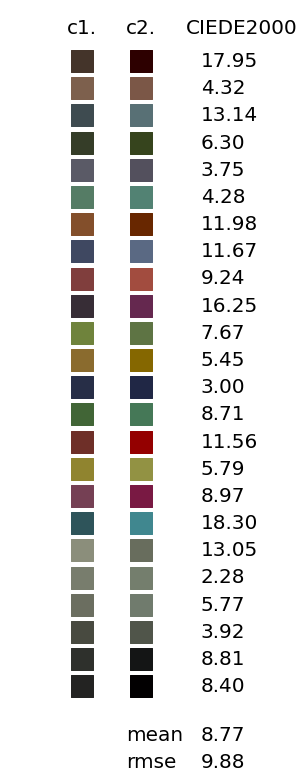

In [16]:
sim_wlis = color_transfer(caps, wli_m)

errs = cal_delta_e_cie2000_rgb(wlis, sim_wlis)

print('rmse',rmse(errs))

plot_diff(wlis, sim_wlis)

In [17]:
img = cv2.imread('img_cap.jpg')
# img = cv2.imread('tar_wli_avg.bmp')

img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

rep_img = color_transfer(img, wli_m)

C:\Users\Tony\AppData\Local\Temp\ipykernel_18888\505996063.py:17: RuntimeWarning: invalid value encountered in power
  gamma = 1.055 * linsrgb**(1./2.4) - 0.055


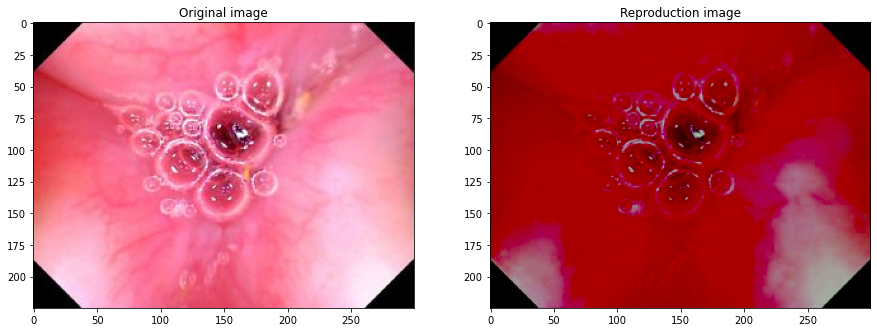

In [18]:
plt.figure(figsize=(15, 6))

plt.subplot(1,2,1)
plt.imshow(img)
plt.title('Original image')

plt.subplot(1,2,2)
plt.imshow(rep_img)
plt.title('Reproduction image')

plt.show()

# Optimize - Color transfer matrix(without spectrum)

In [13]:
def color_transfer(src_data, m):
    
    data_shape = src_data.shape
    
    tar_data = src_data.reshape(-1, data_shape[-1])
    tar_data = np.dot(tar_data, m)
    
    tar_data[tar_data<0] = 0
    tar_data[tar_data>255] = 255
    tar_data = tar_data.astype('uint8')
    tar_data = tar_data.reshape(data_shape)
    
    return tar_data
    
def objective(m):
    
    sim_nbis = color_transfer(wlis, m.reshape(3,3))
    
    errs = cal_delta_e_cie2000_rgb(nbis, sim_nbis)

    return rmse(errs)

# define range for input
r_min, r_max = 0.0, 1.0

v0 = rand(9)
bounds = [[r_min, r_max]] * 9
result = dual_annealing(objective, bounds, x0=v0)

# v0 = rand((int(400 / cmf_gap + 1)) * 3) * 2
# result = basinhopping(objective, v0)

# summarize the result
print('Status : %s' % result['message'])
print('Total Evaluations: %d' % result['nfev'])

# evaluate solution
solution = result['x']
evaluation = objective(solution)

print('rmse', evaluation)

Status : ['Maximum number of iteration reached']
Total Evaluations: 18781
rmse 1.3444850988148795


In [14]:
# update
nbi_m = solution.reshape(3,3)

In [15]:
nbi_m

array([[0.30104582, 0.27813811, 0.15056388],
       [0.9777844 , 0.27150625, 0.54882022],
       [0.01240498, 0.94653874, 0.5063711 ]])

rmse 1.3444850988148795


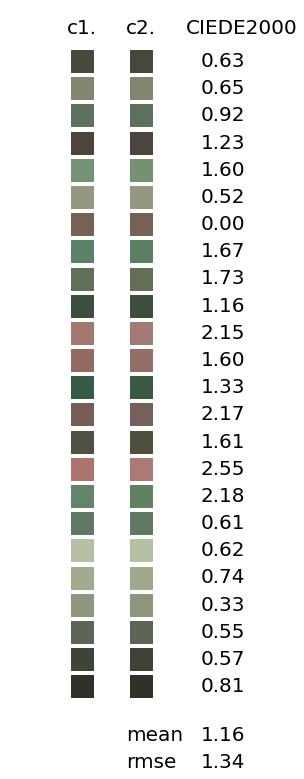

In [16]:
sim_nbis = color_transfer(wlis, nbi_m)

errs = cal_delta_e_cie2000_rgb(nbis, sim_nbis)

print('rmse',rmse(errs))

plot_diff(nbis, sim_nbis)

In [17]:
def sToneCurve(frame):
    look_up_table = np.zeros((256,1), dtype = 'uint8')
    for i in range(256):
        look_up_table[i][0] = 255 * (np.sin(np.pi * (i/255 - 1/2)) + 1) / 2
    return cv2.LUT(frame, look_up_table)

In [26]:
img = cv2.imread('01.jpg')
# img = cv2.imread('tar_wli_avg.bmp')

img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

rep_img = color_transfer(img, nbi_m)
rep_img = sToneCurve(rep_img)

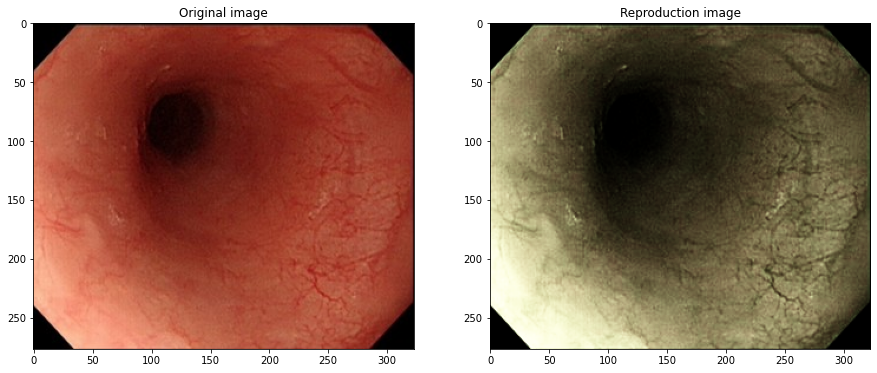

In [27]:
plt.figure(figsize=(15, 6))

plt.subplot(1,2,1)
plt.imshow(img)
plt.title('Original image')

plt.subplot(1,2,2)
plt.imshow(rep_img)
plt.title('Reproduction image')

plt.show()

In [33]:
src_path = r'C:\Users\Tony\Desktop\TEST\01_endoscope\2023-03_Summary\JPEGImages'
tar_path = r'C:\Users\Tony\Desktop\TEST\01_endoscope\2023-03_Summary\JPEGImages_NBI'

# src_path = r'C:\Users\Tony\Desktop\Olympus_wli'
# tar_path = r'C:\Users\Tony\Desktop\Olympus_wli_NBI'

In [34]:
from os import walk
import os
from os import listdir
from os.path import isfile, isdir, join
from os import walk

def filter_ext(files, tar_ext):
    
    tar_files = []
    
    for file in files:
        
        file_ext = os.path.splitext(file)[-1][1:].lower()
        
        if file_ext == tar_ext:
            tar_files.append(file)
        
    return tar_files
    
def get_all_ext_list(tar_path, tar_ext):
    
    all_tar_files = []
    
    for root, dirs, files in walk(tar_path):
        
        tar_files = filter_ext(files, tar_ext.lower())

        if len(tar_files) == 0:
            continue
            
        tar_files = [join(root, file) for file in tar_files]
            
        all_tar_files = all_tar_files + tar_files
        
    return all_tar_files

In [35]:
res_files = get_all_ext_list(src_path, 'jpg')

In [36]:
for index, file in enumerate(res_files):
    
    dump_file = file.replace(src_path, tar_path)
    dump_file_path = os.path.dirname(os.path.abspath(dump_file))
    
    if not os.path.isdir(dump_file_path):
        try:
            os.makedirs(dump_file_path)
        except FileExistsError:
            print("建立路徑異常。")
            
    img = cv2.imread(file)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    nbi = color_transfer(img, nbi_m)
    nbi = nbi.astype('uint8')
    nbi = sToneCurve(nbi)
    nbi = cv2.cvtColor(nbi, cv2.COLOR_RGB2BGR)
    
    cv2.imwrite(dump_file, nbi)
    
    print(index, dump_file)

0 C:\Users\Tony\Desktop\TEST\01_endoscope\2023-03_Summary\JPEGImages_NBI\08888710 (2).jpg
1 C:\Users\Tony\Desktop\TEST\01_endoscope\2023-03_Summary\JPEGImages_NBI\09132978_20141226_WL.jpg
2 C:\Users\Tony\Desktop\TEST\01_endoscope\2023-03_Summary\JPEGImages_NBI\11218613 (2).jpg
3 C:\Users\Tony\Desktop\TEST\01_endoscope\2023-03_Summary\JPEGImages_NBI\14608492 (2).jpg
4 C:\Users\Tony\Desktop\TEST\01_endoscope\2023-03_Summary\JPEGImages_NBI\17491749_20190422_ES_0_10_10.jpg
5 C:\Users\Tony\Desktop\TEST\01_endoscope\2023-03_Summary\JPEGImages_NBI\17491749_20190422_ES_0_46_46.jpg
6 C:\Users\Tony\Desktop\TEST\01_endoscope\2023-03_Summary\JPEGImages_NBI\17491749_20190422_ES_0_7_7.jpg
7 C:\Users\Tony\Desktop\TEST\01_endoscope\2023-03_Summary\JPEGImages_NBI\180518-0938-21.jpg
8 C:\Users\Tony\Desktop\TEST\01_endoscope\2023-03_Summary\JPEGImages_NBI\180518-0938-28.jpg
9 C:\Users\Tony\Desktop\TEST\01_endoscope\2023-03_Summary\JPEGImages_NBI\180518-0938-39.jpg
10 C:\Users\Tony\Desktop\TEST\01_endosco

83 C:\Users\Tony\Desktop\TEST\01_endoscope\2023-03_Summary\JPEGImages_NBI\32573090_20180810_ES_0_9_9.jpg
84 C:\Users\Tony\Desktop\TEST\01_endoscope\2023-03_Summary\JPEGImages_NBI\32648043_20180921_ES_0_10_10.jpg
85 C:\Users\Tony\Desktop\TEST\01_endoscope\2023-03_Summary\JPEGImages_NBI\32648043_20180921_ES_0_11_11.jpg
86 C:\Users\Tony\Desktop\TEST\01_endoscope\2023-03_Summary\JPEGImages_NBI\32648043_20180921_ES_0_12_12.jpg
87 C:\Users\Tony\Desktop\TEST\01_endoscope\2023-03_Summary\JPEGImages_NBI\32648043_20180921_ES_0_13_13.jpg
88 C:\Users\Tony\Desktop\TEST\01_endoscope\2023-03_Summary\JPEGImages_NBI\32648043_20180921_ES_0_14_14.jpg
89 C:\Users\Tony\Desktop\TEST\01_endoscope\2023-03_Summary\JPEGImages_NBI\32648043_20180921_ES_0_15_15.jpg
90 C:\Users\Tony\Desktop\TEST\01_endoscope\2023-03_Summary\JPEGImages_NBI\32648043_20180921_ES_0_16_16.jpg
91 C:\Users\Tony\Desktop\TEST\01_endoscope\2023-03_Summary\JPEGImages_NBI\32648043_20180921_ES_0_17_17.jpg
92 C:\Users\Tony\Desktop\TEST\01_endosc

165 C:\Users\Tony\Desktop\TEST\01_endoscope\2023-03_Summary\JPEGImages_NBI\img0000031741_normal.jpg
166 C:\Users\Tony\Desktop\TEST\01_endoscope\2023-03_Summary\JPEGImages_NBI\img0000031755_normal.jpg
167 C:\Users\Tony\Desktop\TEST\01_endoscope\2023-03_Summary\JPEGImages_NBI\img0000031779_normal.jpg
168 C:\Users\Tony\Desktop\TEST\01_endoscope\2023-03_Summary\JPEGImages_NBI\img0000040879_normal.jpg
169 C:\Users\Tony\Desktop\TEST\01_endoscope\2023-03_Summary\JPEGImages_NBI\img0000040880_normal.jpg
170 C:\Users\Tony\Desktop\TEST\01_endoscope\2023-03_Summary\JPEGImages_NBI\img0000040881_normal.jpg
171 C:\Users\Tony\Desktop\TEST\01_endoscope\2023-03_Summary\JPEGImages_NBI\img0000040882_normal.jpg
172 C:\Users\Tony\Desktop\TEST\01_endoscope\2023-03_Summary\JPEGImages_NBI\img0000040883_normal.jpg
173 C:\Users\Tony\Desktop\TEST\01_endoscope\2023-03_Summary\JPEGImages_NBI\img0000040884_normal.jpg
174 C:\Users\Tony\Desktop\TEST\01_endoscope\2023-03_Summary\JPEGImages_NBI\img0000043046_normal.jpg


250 C:\Users\Tony\Desktop\TEST\01_endoscope\2023-03_Summary\JPEGImages_NBI\img0007098733_normal.jpg
251 C:\Users\Tony\Desktop\TEST\01_endoscope\2023-03_Summary\JPEGImages_NBI\img0007098763_normal.jpg
252 C:\Users\Tony\Desktop\TEST\01_endoscope\2023-03_Summary\JPEGImages_NBI\img0007098969_normal.jpg
253 C:\Users\Tony\Desktop\TEST\01_endoscope\2023-03_Summary\JPEGImages_NBI\img0007099163_normal.jpg
254 C:\Users\Tony\Desktop\TEST\01_endoscope\2023-03_Summary\JPEGImages_NBI\img0007099289_normal.jpg
255 C:\Users\Tony\Desktop\TEST\01_endoscope\2023-03_Summary\JPEGImages_NBI\img0007099297_normal.jpg
256 C:\Users\Tony\Desktop\TEST\01_endoscope\2023-03_Summary\JPEGImages_NBI\img0007099371_normal.jpg
257 C:\Users\Tony\Desktop\TEST\01_endoscope\2023-03_Summary\JPEGImages_NBI\img0007099435_normal.jpg
258 C:\Users\Tony\Desktop\TEST\01_endoscope\2023-03_Summary\JPEGImages_NBI\img0007099441_normal.jpg
259 C:\Users\Tony\Desktop\TEST\01_endoscope\2023-03_Summary\JPEGImages_NBI\img0007099447_normal.jpg


332 C:\Users\Tony\Desktop\TEST\01_endoscope\2023-03_Summary\JPEGImages_NBI\Img20200729-092515404.jpg
333 C:\Users\Tony\Desktop\TEST\01_endoscope\2023-03_Summary\JPEGImages_NBI\Img20200729-092518991.jpg
334 C:\Users\Tony\Desktop\TEST\01_endoscope\2023-03_Summary\JPEGImages_NBI\Img20200729-092521425.jpg
335 C:\Users\Tony\Desktop\TEST\01_endoscope\2023-03_Summary\JPEGImages_NBI\Img20200729-092527725.jpg
336 C:\Users\Tony\Desktop\TEST\01_endoscope\2023-03_Summary\JPEGImages_NBI\Img20200729-092530426.jpg
337 C:\Users\Tony\Desktop\TEST\01_endoscope\2023-03_Summary\JPEGImages_NBI\Img20200729-092534995.jpg
338 C:\Users\Tony\Desktop\TEST\01_endoscope\2023-03_Summary\JPEGImages_NBI\Img20200729-092542659.jpg
339 C:\Users\Tony\Desktop\TEST\01_endoscope\2023-03_Summary\JPEGImages_NBI\Img20200729-092545794.jpg
340 C:\Users\Tony\Desktop\TEST\01_endoscope\2023-03_Summary\JPEGImages_NBI\Img20200729-092552858.jpg
341 C:\Users\Tony\Desktop\TEST\01_endoscope\2023-03_Summary\JPEGImages_NBI\Img20200729-1053

...

3051 C:\Users\Tony\Desktop\TEST\01_endoscope\2023-03_Summary\JPEGImages_NBI\REC20220614-101619622__003869.jpg
3052 C:\Users\Tony\Desktop\TEST\01_endoscope\2023-03_Summary\JPEGImages_NBI\REC20220614-101619622__003881.jpg
3053 C:\Users\Tony\Desktop\TEST\01_endoscope\2023-03_Summary\JPEGImages_NBI\REC20220614-101619622__004791.jpg
3054 C:\Users\Tony\Desktop\TEST\01_endoscope\2023-03_Summary\JPEGImages_NBI\REC20220614-101619622__004805.jpg
3055 C:\Users\Tony\Desktop\TEST\01_endoscope\2023-03_Summary\JPEGImages_NBI\REC20220614-101619622__004813.jpg
3056 C:\Users\Tony\Desktop\TEST\01_endoscope\2023-03_Summary\JPEGImages_NBI\REC20220614-101619622__004823.jpg
3057 C:\Users\Tony\Desktop\TEST\01_endoscope\2023-03_Summary\JPEGImages_NBI\REC20220614-101619622__004833.jpg
3058 C:\Users\Tony\Desktop\TEST\01_endoscope\2023-03_Summary\JPEGImages_NBI\REC20220614-101619622__004843.jpg
3059 C:\Users\Tony\Desktop\TEST\01_endoscope\2023-03_Summary\JPEGImages_NBI\REC20220614-101619622__004869.jpg
3060 C:\Us

3132 C:\Users\Tony\Desktop\TEST\01_endoscope\2023-03_Summary\JPEGImages_NBI\REC20220707-085221343__000429.jpg
3133 C:\Users\Tony\Desktop\TEST\01_endoscope\2023-03_Summary\JPEGImages_NBI\REC20220707-085221343__000453.jpg
3134 C:\Users\Tony\Desktop\TEST\01_endoscope\2023-03_Summary\JPEGImages_NBI\REC20220707-085221343__000461.jpg
3135 C:\Users\Tony\Desktop\TEST\01_endoscope\2023-03_Summary\JPEGImages_NBI\REC20220707-085221343__000465.jpg
3136 C:\Users\Tony\Desktop\TEST\01_endoscope\2023-03_Summary\JPEGImages_NBI\REC20220707-085221343__000469.jpg
3137 C:\Users\Tony\Desktop\TEST\01_endoscope\2023-03_Summary\JPEGImages_NBI\REC20220707-085221343__000471.jpg
3138 C:\Users\Tony\Desktop\TEST\01_endoscope\2023-03_Summary\JPEGImages_NBI\REC20220707-085221343__000503.jpg
3139 C:\Users\Tony\Desktop\TEST\01_endoscope\2023-03_Summary\JPEGImages_NBI\REC20220707-085221343__000561.jpg
3140 C:\Users\Tony\Desktop\TEST\01_endoscope\2023-03_Summary\JPEGImages_NBI\REC20220707-085221343__000565.jpg
3141 C:\Us

3210 C:\Users\Tony\Desktop\TEST\01_endoscope\2023-03_Summary\JPEGImages_NBI\REC20220824-093449384__000025.jpg
3211 C:\Users\Tony\Desktop\TEST\01_endoscope\2023-03_Summary\JPEGImages_NBI\REC20220824-093449384__000035.jpg
3212 C:\Users\Tony\Desktop\TEST\01_endoscope\2023-03_Summary\JPEGImages_NBI\REC20220824-093449384__000049.jpg
3213 C:\Users\Tony\Desktop\TEST\01_endoscope\2023-03_Summary\JPEGImages_NBI\REC20220824-093449384__000117.jpg
3214 C:\Users\Tony\Desktop\TEST\01_endoscope\2023-03_Summary\JPEGImages_NBI\REC20220824-093449384__000121.jpg
3215 C:\Users\Tony\Desktop\TEST\01_endoscope\2023-03_Summary\JPEGImages_NBI\REC20220824-093449384__000129.jpg
3216 C:\Users\Tony\Desktop\TEST\01_endoscope\2023-03_Summary\JPEGImages_NBI\REC20220824-093449384__000133.jpg
3217 C:\Users\Tony\Desktop\TEST\01_endoscope\2023-03_Summary\JPEGImages_NBI\REC20220824-093449384__000141.jpg
3218 C:\Users\Tony\Desktop\TEST\01_endoscope\2023-03_Summary\JPEGImages_NBI\REC20220824-093449384__000149.jpg
3219 C:\Us

3299 C:\Users\Tony\Desktop\TEST\01_endoscope\2023-03_Summary\JPEGImages_NBI\S11.jpg
3300 C:\Users\Tony\Desktop\TEST\01_endoscope\2023-03_Summary\JPEGImages_NBI\S12 (2).jpg
3301 C:\Users\Tony\Desktop\TEST\01_endoscope\2023-03_Summary\JPEGImages_NBI\S12.jpg
3302 C:\Users\Tony\Desktop\TEST\01_endoscope\2023-03_Summary\JPEGImages_NBI\S13 (2).jpg
3303 C:\Users\Tony\Desktop\TEST\01_endoscope\2023-03_Summary\JPEGImages_NBI\S13 (3).jpg
3304 C:\Users\Tony\Desktop\TEST\01_endoscope\2023-03_Summary\JPEGImages_NBI\S13.jpg
3305 C:\Users\Tony\Desktop\TEST\01_endoscope\2023-03_Summary\JPEGImages_NBI\S14 (2).jpg
3306 C:\Users\Tony\Desktop\TEST\01_endoscope\2023-03_Summary\JPEGImages_NBI\S14.jpg
3307 C:\Users\Tony\Desktop\TEST\01_endoscope\2023-03_Summary\JPEGImages_NBI\S16 (2).jpg
3308 C:\Users\Tony\Desktop\TEST\01_endoscope\2023-03_Summary\JPEGImages_NBI\S16.jpg
3309 C:\Users\Tony\Desktop\TEST\01_endoscope\2023-03_Summary\JPEGImages_NBI\S17 (2).jpg
3310 C:\Users\Tony\Desktop\TEST\01_endoscope\2023-03

3403 C:\Users\Tony\Desktop\TEST\01_endoscope\2023-03_Summary\JPEGImages_NBI\S71.jpg
3404 C:\Users\Tony\Desktop\TEST\01_endoscope\2023-03_Summary\JPEGImages_NBI\S87.jpg
3405 C:\Users\Tony\Desktop\TEST\01_endoscope\2023-03_Summary\JPEGImages_NBI\S89 (2).jpg
3406 C:\Users\Tony\Desktop\TEST\01_endoscope\2023-03_Summary\JPEGImages_NBI\S89.jpg
3407 C:\Users\Tony\Desktop\TEST\01_endoscope\2023-03_Summary\JPEGImages_NBI\S90 (2).jpg
3408 C:\Users\Tony\Desktop\TEST\01_endoscope\2023-03_Summary\JPEGImages_NBI\S90.jpg
3409 C:\Users\Tony\Desktop\TEST\01_endoscope\2023-03_Summary\JPEGImages_NBI\S91.jpg
3410 C:\Users\Tony\Desktop\TEST\01_endoscope\2023-03_Summary\JPEGImages_NBI\S93.jpg
3411 C:\Users\Tony\Desktop\TEST\01_endoscope\2023-03_Summary\JPEGImages_NBI\S96.jpg
3412 C:\Users\Tony\Desktop\TEST\01_endoscope\2023-03_Summary\JPEGImages_NBI\WL (2).jpg
3413 C:\Users\Tony\Desktop\TEST\01_endoscope\2023-03_Summary\JPEGImages_NBI\WL.jpg
3414 C:\Users\Tony\Desktop\TEST\01_endoscope\2023-03_Summary\JPEGI

# Optimize - Spectrum transfer matrix(with spectrum)

In [ ]:
spec_gap = 20
spec_usage = int(401 / spec_gap) + 1 

def spectrum_transfer(src_data, m):
    
    data_shape = src_data.shape
    
    tar_data = src_data.reshape(-1, data_shape[-1])
    tar_data = np.dot(tar_data, m) * 255
    
    tar_data[tar_data<0] = 0
    tar_data[tar_data>255] = 255
    tar_data = tar_data.astype('uint8')
    tar_data = tar_data.reshape(data_shape[0:-1] + (3,))
    
    return tar_data
    
def objective(m):
    
    sim_nbis = spectrum_transfer(wli_specs[:, ::spec_gap], m.reshape(spec_usage,3))
    
    errs = cal_delta_e_cie2000_rgb(nbis, sim_nbis)

    return rmse(errs)


run_times = 5

rmses = []
res_list = []

for i in range(run_times):
    
    print('run: %d'%i)

    # define range for input
    r_min, r_max = 0.0, 2.0

    v0 = rand(spec_usage * 3)
    bounds = [[r_min, r_max]] * spec_usage * 3
    result = dual_annealing(objective, bounds, x0=v0)

    # result = basinhopping(objective, v0)

    # summarize the result
    print('Status : %s' % result['message'])
    print('Total Evaluations: %d' % result['nfev'])

    # evaluate solution
    solution = result['x']
    evaluation = objective(solution)

    print('rmse', evaluation)
    
    rmses.append(evaluation)
    res_list.append(solution)

run: 0
Status : ['Maximum number of iteration reached']
Total Evaluations: 126129
rmse 45.399085337474496
run: 1
Status : ['Maximum number of iteration reached']
Total Evaluations: 126129
rmse 45.41462512004815
run: 2
Status : ['Maximum number of iteration reached']
Total Evaluations: 126065
rmse 45.41462512004815
run: 3
Status : ['Maximum number of iteration reached']
Total Evaluations: 126065
rmse 45.41462512004815
run: 4


In [ ]:
solution = res_list[2]

In [ ]:
# update
spec_nbi_m = solution.reshape(spec_usage,3)

In [ ]:
spec_sim_nbis = spectrum_transfer(wli_specs[:, ::spec_gap], spec_nbi_m)

errs = cal_delta_e_cie2000_rgb(nbis, spec_sim_nbis)

print('rmse',rmse(errs))

plot_diff(nbis, spec_sim_nbis)

In [ ]:
img = cv2.imread('en_img.jpg')
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

img_specs = transfer.transfer(img)

rep_img = spectrum_transfer(img_specs[:,:, ::spec_gap], spec_nbi_m)

In [ ]:
plt.figure(figsize=(15, 6))

plt.subplot(1,2,1)
plt.imshow(img)
plt.title('Original image')

plt.subplot(1,2,2)
plt.imshow(rep_img)
plt.title('Reproduction image')

plt.show()